# 01 · Preprocessing — Rendeiro et al. 2020 (Hematologic, CLL)

Malignant compartment of a chronic lymphocytic leukemia 10x atlas: 12 longitudinal ibrutinib samples across **4 patients** (CLL1, CLL5, CLL6, CLL8). Loads malignant cells, derives a min-cell threshold from the data, selects overdispersed genes, runs PCA -> Harmony(sample) -> UMAP -> Leiden, scores the cell cycle and the three embryonic signatures, and settles **Gate 1** (mixing + continuity) on the regenerated embedding across a theta x n_pcs sweep with per-neighbourhood iLISI — never on a scalar.

**Prior-attempt caution.** Five prior autonomous runs failed the science here, oscillating between a forced 'linear GO' (theta=5–10, one over-integrated mass) and an 'archipelago NO-GO' (theta=2). Both were rejected. This run judges Gate 1 on the embedding + iLISI and adds a signature-**geography** test the priors never computed.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import scipy.stats as ss
import warnings; warnings.filterwarnings('ignore')
np.random.seed(0)
sc.settings.verbosity = 1

In [2]:
# paths (this dataset sits two levels deeper than Puram: Claude/<Category>/<Dataset-suffix>/)
name = os.path.split(os.getcwd())[1]                       # 'Rendeiro2020_Hematologic-5'
base = name.split('-')[0]                                   # -> 'Rendeiro2020_Hematologic'
pth  = os.path.join('..', '..', '..', '..')          # up to EMToolbox root
sys.path.append(os.path.join(pth,'mesencontext','scripts'))
from load import load_CCCA_adata
pth_in  = os.path.join(pth,'data','unzip','CCCA', f'Data_{base}')
pth_out = os.path.join(pth,'data','cancer', 'vertebrate', 'CCCA', 'claude','Hematologic', name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude','Hematologic', name)
pth_gene= os.path.join(pth,'data','features','biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True)

In [3]:
# load dataset -> malignant cells (loader auto-detects normalization + log1p)
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
raw_n = adata.n_obs
print('malignant cells:', raw_n, '| log1p X max = %.2f' % float(adata.X.max()))
adata

Loading ../../../../../../data/unzip/CCCA/Data_Rendeiro2020_Hematologic
Done.
malignant cells: 18854 | log1p X max = 6.35


AnnData object with n_obs × n_vars = 18854 × 18402
    obs: 'sample', 'patient', 'timepoint', 'cell_type', 'complexity', 'celltype'
    uns: 'log1p'

### Derive the min-cell threshold from the count distribution
Find the dominant *multiplicative* gap in per-sample counts rather than copying a fixed cutoff.

In [4]:
n = adata.obs['sample'].value_counts().sort_values(ascending=False)
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]; gap = int(ratios.argmax())
print(n.to_string())
print(f'\nlargest multiplicative gap: {n.index[gap]}({int(vals[gap])}) -> {n.index[gap+1]}({int(vals[gap+1])}) '
      f'= {ratios[gap]:.2f}x  (next-largest {sorted(ratios)[-2]:.2f}x)')

sample
CLL5_d0      5074
CLL6_d30     4353
CLL5_d30     2818
CLL1_d0      2267
CLL6_d120    1575
CLL8_d0      1558
CLL6_d0      1012
CLL5_d150      80
CLL8_d30       78
CLL6_d280      33
CLL1_d120       6

largest multiplicative gap: CLL6_d0(1012) -> CLL5_d150(80) = 12.65x  (next-largest 5.50x)


In [5]:
keep = n.index[n >= 100]                       # threshold above the 12.65x cliff
adata = adata[adata.obs['sample'].isin(keep)].copy()
after_thr = adata.n_obs
print(f'kept {len(keep)}/{len(n)} samples -> {after_thr} cells across {adata.obs.patient.nunique()} patients')
print(adata.obs.patient.value_counts().to_string())

kept 7/11 samples -> 18657 cells across 4 patients
patient
CLL5    7892
CLL6    6940
CLL1    2267
CLL8    1558


In [6]:
sc.pp.filter_genes(adata, min_cells=3)
print('genes:', adata.n_vars)

genes: 14889


### Cell-cycle scoring (Tirosh/Regev)
CLL B-cells are highly proliferative; score the cycle now to test later whether the embryonic modules are cell-cycle-confounded (the recurring atlas failure mode).

In [7]:
s_genes=['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1',
  'MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2',
  'RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes=['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF',
  'TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP',
  'CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR',
  'AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
adata.obs['cycling_score']=adata.obs[['S_score','G2M_score']].max(axis=1)
print('phase:', adata.obs.phase.value_counts().to_dict())
print('cycling fraction (S+G2M): %.3f' % (adata.obs.phase!='G1').mean())

phase: {'G1': 10793, 'S': 6605, 'G2M': 1259}
cycling fraction (S+G2M): 0.422


### Overdispersed genes -> PCA (no scaling)
`sc.pp.scale` is absent from the reference protocol.

In [8]:
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 528 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 528


## Gate 1 — integration sweep with per-neighbourhood iLISI
Harmony on `sample` across theta = 1/2/3/5/10 x n_pcs = 20/30/40. iLISI = median inverse-Simpson effective label count in each cell's kNN (ceiling = #samples=7 / #patients=4). We report BOTH sample and patient iLISI: genuine shared biology would drive **patient** iLISI toward its ceiling; a forced merge of patient-private clones will not.

In [9]:
def ilisi(emb, labels, k=90, n_sub=4000, seed=0):
    rng=np.random.default_rng(seed); labs=pd.Categorical(labels); codes=labs.codes; L=len(labs.categories)
    idx=rng.choice(emb.shape[0], min(n_sub,emb.shape[0]), replace=False)
    _,nn=cKDTree(emb).query(emb[idx], k=k+1); nn=nn[:,1:]
    out=np.empty(len(idx))
    for i in range(len(idx)):
        p=np.bincount(codes[nn[i]], minlength=L)/k; out[i]=1.0/np.sum(p**2)
    return float(np.median(out))
samp=adata.obs['sample'].values; pat=adata.obs['patient'].values
nS=adata.obs['sample'].nunique(); nP=adata.obs['patient'].nunique()
rows=[]
for theta in [1,2,3,5,10]:
    adt=adata.copy(); sce.pp.harmony_integrate(adt,'sample',theta=theta,max_iter_harmony=20)
    for npcs in [20,30,40]:
        emb=adt.obsm['X_pca_harmony'][:,:npcs]
        rows.append((theta,npcs,ilisi(emb,samp),ilisi(emb,pat)))
sweep=pd.DataFrame(rows,columns=['theta','n_pcs','iLISI_sample','iLISI_patient'])
print(f'ceilings: sample={nS}  patient={nP}')
print(sweep.to_string(index=False))

ceilings: sample=7  patient=4
 theta  n_pcs  iLISI_sample  iLISI_patient
     1     20      2.060021       1.254258
     1     30      2.153683       1.305189
     1     40      2.228949       1.374745
     2     20      2.906351       1.625853
     2     30      3.156664       1.758195
     2     40      3.302080       1.925820
     3     20      4.170958       2.301137
     3     30      4.397394       2.454545
     3     40      4.537817       2.635003
     5     20      4.731308       2.599487
     5     30      4.915049       2.747626
     5     40      5.006180       2.932657
    10     20      4.951100       2.703605
    10     30      5.152672       2.866242
    10     40      5.246114       3.061224


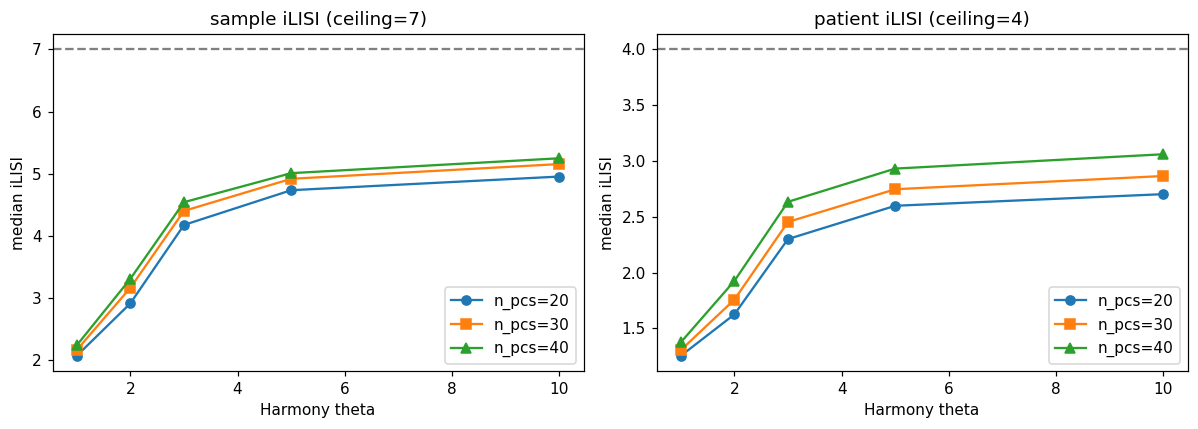

In [10]:
# visualize the sweep
fig,axs=plt.subplots(1,2,figsize=(11,4))
for npcs,mk in zip([20,30,40],['o','s','^']):
    d=sweep[sweep.n_pcs==npcs]
    axs[0].plot(d.theta,d.iLISI_sample,mk+'-',label=f'n_pcs={npcs}')
    axs[1].plot(d.theta,d.iLISI_patient,mk+'-',label=f'n_pcs={npcs}')
axs[0].axhline(nS,ls='--',c='grey'); axs[0].set_title('sample iLISI (ceiling=%d)'%nS)
axs[1].axhline(nP,ls='--',c='grey'); axs[1].set_title('patient iLISI (ceiling=%d)'%nP)
for a in axs: a.set_xlabel('Harmony theta'); a.set_ylabel('median iLISI'); a.legend()
fig.tight_layout(); plt.show()

iLISI rises with theta but the **patient** curve plateaus far below its ceiling of 4 — the first sign that Harmony is forcing a merge of patient-private clones rather than revealing shared biology.

In [11]:
# kNN patient-purity vs integration strength (the decisive archipelago test)
def knn_pat_acc(emb,labels,k=30,n_sub=6000,seed=0):
    rng=np.random.default_rng(seed); idx=rng.choice(emb.shape[0],min(n_sub,emb.shape[0]),replace=False)
    _,nn=cKDTree(emb).query(emb[idx],k=k+1); nn=nn[:,1:]; lab=np.asarray(labels); ok=0
    for i in range(len(idx)):
        v,ct=np.unique(lab[nn[i]],return_counts=True)
        ok += v[ct.argmax()]==lab[idx[i]]
    return ok/len(idx)
prev=pd.Series(pat).value_counts(normalize=True)
print('patient prevalence:',prev.round(3).to_dict())
print('chance same-patient sum p^2 = %.3f | majority-class acc = %.3f'%((prev**2).sum(),prev.max()))
print('UNINTEGRATED PCA20 kNN patient acc = %.3f'%knn_pat_acc(adata.obsm['X_pca'][:,:20],pat))
for theta in [2,5,10]:
    adt=adata.copy(); sce.pp.harmony_integrate(adt,'sample',theta=theta,max_iter_harmony=20)
    print(f'theta={theta:2d} kNN patient acc = %.3f'%knn_pat_acc(adt.obsm['X_pca_harmony'][:,:20],pat))

patient prevalence: {'CLL5': 0.423, 'CLL6': 0.372, 'CLL1': 0.122, 'CLL8': 0.084}
chance same-patient sum p^2 = 0.339 | majority-class acc = 0.423
UNINTEGRATED PCA20 kNN patient acc = 0.997
theta= 2 kNN patient acc = 0.749
theta= 5 kNN patient acc = 0.548
theta=10 kNN patient acc = 0.520


Unintegrated kNN patient accuracy is ~**99.7%** — each patient's clone is its own island. Even at theta=10 it only falls to ~**52%** (chance 34%, majority-class 42%): integration merges the clones only by force, never to random mixing.

In [12]:
# canonical embedding: theta=2 (biology-preserving, reveals the archipelago)
sce.pp.harmony_integrate(adata,'sample',theta=2,max_iter_harmony=20)
sc.pp.neighbors(adata,n_pcs=20,n_neighbors=30,use_rep='X_pca_harmony')
sc.tl.umap(adata,spread=1.3,random_state=0)

In [13]:
# remove detached specks (radius graph 6x median-NN, keep largest component; 2 rounds)
def remove_specks(ad):
    emb=ad.obsm['X_umap']; t=cKDTree(emb); d,_=t.query(emb,k=2); r=6*np.median(d[:,1])
    pr=t.query_pairs(r,output_type='ndarray'); N=emb.shape[0]
    M=coo_matrix((np.ones(len(pr)),(pr[:,0],pr[:,1])),shape=(N,N))
    _,lab=connected_components(M+M.T,directed=False)
    keep=lab==pd.Series(lab).value_counts().idxmax(); return keep
before=adata.n_obs
for _ in range(2):
    adata=adata[remove_specks(adata)].copy()
print('removed', before-adata.n_obs, 'speck cells ->', adata.n_obs)
sc.pp.neighbors(adata,n_pcs=20,n_neighbors=30,use_rep='X_pca_harmony')
sc.tl.umap(adata,spread=1.3,random_state=0)
sc.tl.leiden(adata,resolution=0.3,random_state=0)

removed 59 speck cells -> 18598


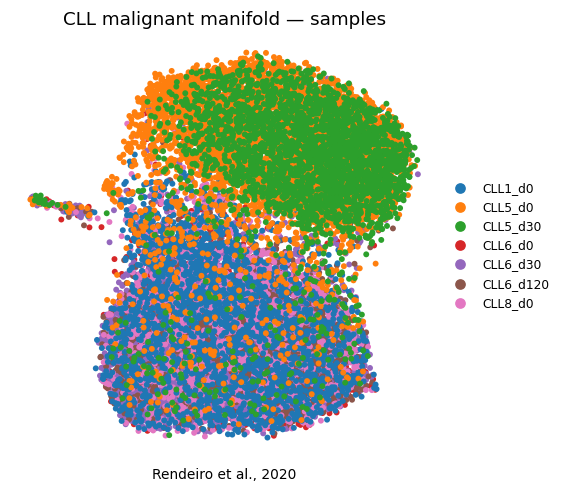

In [14]:
# sample integration figure (canonical orientation)
fig,ax=plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata,color='sample',size=60,frameon=False,show=False,ax=ax,title='CLL malignant manifold — samples')
ax.invert_yaxis(); ax.invert_xaxis()
h,l=ax.get_legend_handles_labels()
ax.legend(h,l,ncol=1,frameon=False,loc='center left',bbox_to_anchor=(1.0,0.5),fontsize=8)
ax.text(.5,-.05,'Rendeiro et al., 2020',ha='center',transform=ax.transAxes,fontsize=9)
fig.savefig(os.path.join(pth_fig,'samples.pdf'),bbox_inches='tight'); plt.show()

The manifold splits into a **CLL5 lobe** (the BTK-mutant progressor, top) and a **CLL1/6/8 lobe** (bottom) — patient identity, not a shared cell-state axis. This is the visual basis of the Gate 1 call.

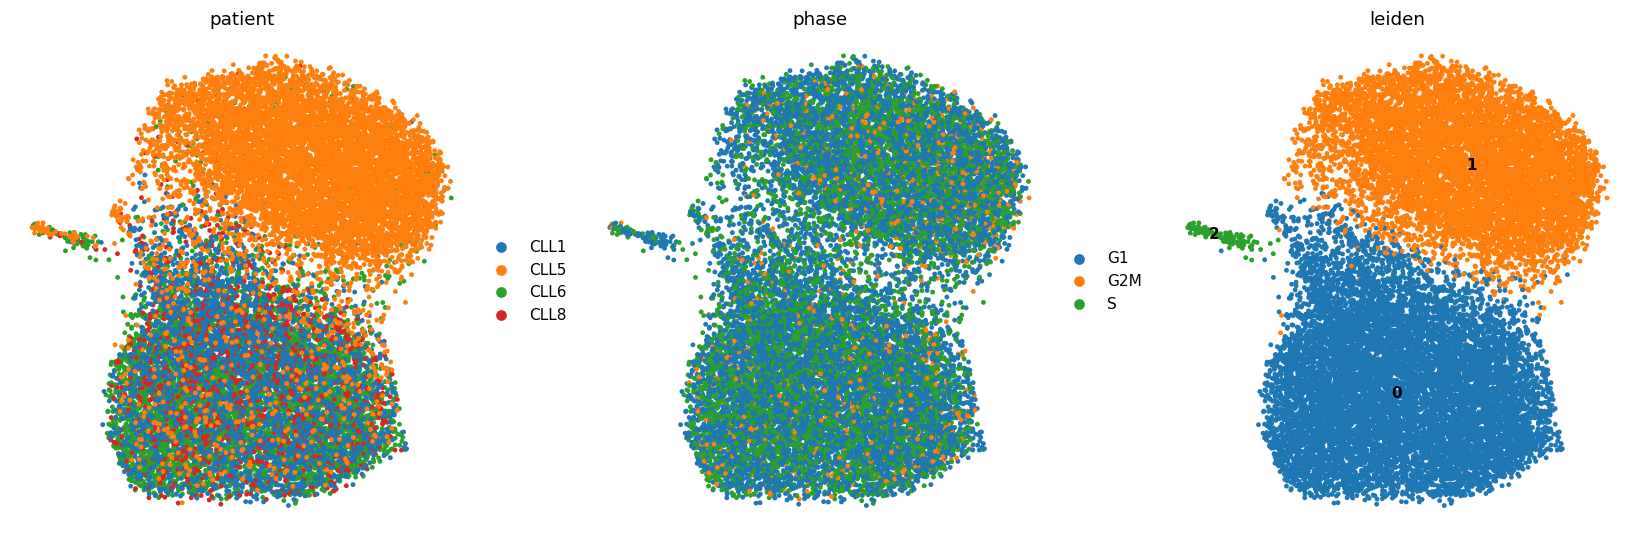

In [15]:
# patient / phase / leiden panels
fig,axs=plt.subplots(1,3,figsize=(15,5))
for ax,cc in zip(axs,['patient','phase','leiden']):
    sc.pl.umap(adata,color=cc,size=40,frameon=False,show=False,ax=ax,
               legend_loc='on data' if cc=='leiden' else 'right margin',title=cc)
    ax.invert_yaxis(); ax.invert_xaxis()
fig.tight_layout(); plt.show()

### Signature scoring + the geography test
Score Gast/pSom/Crest with the **union** control pool, then test spatial structure with Moran's I on the kNN graph and compare to a random-signature control. A real developmental gradient gives Moran's I >> control; a structureless blob gives Moran's I ≈ control.

In [16]:
def load_set(fn): return pd.read_csv(os.path.join(pth_gene,fn))['hsapiens'].dropna().drop_duplicates().tolist()
sets={'Gast':load_set('GSE162534.csv'),'pSom':load_set('GSE229103.csv'),'Crest':load_set('rRNAModifications.csv')}
union=load_set('union.csv'); up=[g for g in union if g in adata.var_names]
for nm,gs in sets.items():
    sc.tl.score_genes(adata,[g for g in gs if g in adata.var_names],ctrl_size=50,gene_pool=up,score_name=nm,random_state=0)
print('raw module means: Gast %.4f  pSom %.4f  Crest %.4f'%(adata.obs.Gast.mean(),adata.obs.pSom.mean(),adata.obs.Crest.mean()))

raw module means: Gast -0.0137  pSom 0.0054  Crest 0.0093


In [17]:
# Moran's I geography vs random-signature control
mi=sc.metrics.morans_i(adata, vals=np.vstack([adata.obs.Gast,adata.obs.pSom,adata.obs.Crest]))
rng=np.random.default_rng(0); ctrl=[]
for rep in range(10):
    sc.tl.score_genes(adata,list(rng.choice(up,60,replace=False)),ctrl_size=50,gene_pool=up,score_name='RND',random_state=rep)
    ctrl.append(sc.metrics.morans_i(adata,vals=adata.obs['RND'].values[None,:])[0])
for nm,v in zip(['Gast','pSom','Crest'],mi): print(f"Moran's I {nm}: {v:+.3f}")
print(f"CONTROL random-signature Moran's I: {np.mean(ctrl):+.3f} +/- {np.std(ctrl):.3f}")

Moran's I Gast: +0.022
Moran's I pSom: +0.019
Moran's I Crest: +0.017
CONTROL random-signature Moran's I: +0.021 +/- 0.014


In [18]:
# cell-cycle confound check + cross-repression axis (informs Gate 2/3, which are not reached)
cc=adata.obs['cycling_score']
for nm in ['Gast','pSom','Crest']:
    print(f'{nm}: r(cell-cycle)={ss.pearsonr(adata.obs[nm],cc)[0]:+.3f}')
print('within/pooled Gast-pSom r = %+.3f (co-vary, no cross-repression)'%ss.pearsonr(adata.obs.Gast,adata.obs.pSom)[0])

Gast: r(cell-cycle)=+0.016
pSom: r(cell-cycle)=-0.001
Crest: r(cell-cycle)=-0.014
within/pooled Gast-pSom r = +0.050 (co-vary, no cross-repression)


**Gate 1 = NO-GO.** The malignant compartment is a per-patient clonal archipelago (unintegrated kNN patient acc 99.7%; theta=10 still 52%, chance 34%), patient iLISI never reaches ceiling, and the embryonic signatures carry no manifold geography (Moran's I ≈ random control). Modules are cell-cycle-orthogonal (r≈+0.02), so there is no cycling lobe to scope; Gast/pSom co-vary (+0.05) — not a branching hub. Per the deliverable spec, the gate chain stops here: only **01_preprocessing** + the unconditional **02_expression** are produced (no manifold / signatures / correlation / modules notebooks).

In [19]:
# store provenance + save processed.h5ad
adata.uns['gate1']={'call':'NO-GO','raw':int(raw_n),'after_threshold':int(after_thr),
                    'after_island':int(adata.n_obs)}
adata.write(os.path.join(pth_out,'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (18598, 14889)
